# CALOR Y MAYORES EN MADRID

## Isócronas: el entorno de 15 minutos andando de cada centro de mayores

**Isócrona normal:** las calles que una persona mayor alcanza en 15 minutos andando a 0,8 m/s (720 m), por la red peatonal de OpenStreetMap.
**Uso en el proyecto:** cada isócrona define el área de influencia del centro, es decir, los hexágonos donde el modelo evaluará intervenciones.

## 1. Preparación y - importamos las librerías

In [1]:
import sys
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import osmnx as ox
import networkx as nx

sys.path.append("../scrips")
from config import RUTA_RAW, RUTA_CLEAN, CRS_PROYECTO

**Decisión:** velocidad de 0,8 m/s, la velocidad media al caminar de las mujeres de 65 años o más (0,9 m/s en los hombres) según Asher y colaboradores (2012, Age and Ageing), con 3.145 personas mayores. Es un valor prudente, porque las mujeres son mayoría en los centros de mayores. Se usan 15 minutos, el criterio de la ciudad de 15 minutos. Distancia máxima: 0,8 × 15 × 60 = 720 m.

In [2]:
VELOCIDAD = 0.8
MINUTOS = 15
DISTANCIA_MAXIMA = VELOCIDAD * MINUTOS * 60
MARGEN_CALLE = 25

print("Distancia máxima:", DISTANCIA_MAXIMA, "m")

Distancia máxima: 720.0 m


**Observación:** la distancia máxima de la isócrona es de 720 m, lo que recorre una persona mayor en 15 minutos a 0,8 m/s.
**MARGEN_CALLE:** los metros que se añaden a cada lado de una calle alcanzada para formar el polígono (las aceras y los edificios que dan a ella).

- cargamos la red peatonal y la pasamos a metros

In [3]:
red = ox.load_graphml(RUTA_RAW + "osm/walk_graph_madrid.graphml")
red = ox.project_graph(red, to_crs=CRS_PROYECTO)
nodos, tramos = ox.graph_to_gdfs(red)

print("Nodos:", len(nodos), "- tramos:", len(tramos))
tramos["length"].describe()

Nodos: 220894 - tramos: 668278


count    668278.000000
mean         44.454306
std          68.294523
min           0.025377
25%           9.856405
50%          22.936808
75%          55.573998
max        5486.116700
Name: length, dtype: float64

**Observación:** la red tiene 220.894 cruces y 668.278 tramos, con una longitud mediana de 23 m; los tramos muy largos (hasta 5,5 km) son caminos por parques y zonas sin urbanizar.

- cargamos los centros y buscamos el cruce más cercano a cada uno

In [4]:
centros = gpd.read_file(RUTA_CLEAN + "centros_mayores.gpkg")
nodos_salida, distancias_nodo = ox.distance.nearest_nodes(red, X=centros["x"], Y=centros["y"], return_dist=True)
centros["nodo"] = nodos_salida
centros["dist_nodo"] = np.round(distancias_nodo, 1)

print("Centros:", len(centros))
centros["dist_nodo"].describe()

Centros: 439


count    439.000000
mean      26.827790
std       17.323574
min        3.100000
25%       15.750000
50%       22.300000
75%       33.800000
max      115.400000
Name: dist_nodo, dtype: float64

**Observación:** todos los centros tienen un cruce a menos de 115 m (mediana de 22 m), así que el punto de salida de cada isócrona es fiable.

## 2. Cálculo de las isócronas y - recorremos la red desde cada centro hasta 720 m y formamos el polígono con las calles alcanzadas

In [5]:
poligonos = []
n_nodos = []

for nodo in centros["nodo"]:
    alcanzados = nx.single_source_dijkstra_path_length(red, nodo, cutoff=DISTANCIA_MAXIMA, weight="length")
    tramos_alcanzados = tramos[
        tramos.index.get_level_values("u").isin(alcanzados) &
        tramos.index.get_level_values("v").isin(alcanzados)
    ]
    poligonos.append(tramos_alcanzados.buffer(MARGEN_CALLE).union_all())
    n_nodos.append(len(alcanzados))

isocronas = gpd.GeoDataFrame(
    centros[["codigo", "nombre", "tipo_centro", "plazas", "dist_nodo"]].copy(),
    geometry=poligonos,
    crs=CRS_PROYECTO
)
isocronas["n_nodos"] = n_nodos
isocronas["area_km2"] = (isocronas.area / 1_000_000).round(3)
isocronas[["n_nodos", "area_km2"]].describe()

,n_nodos,area_km2
count,439.000000,439.000000
mean,664.890661,0.694554
std,321.550087,0.189318
min,67.000000,0.095000
25%,440.500000,0.570000
50%,647.000000,0.736000
75%,836.000000,0.836000
max,1947.000000,1.108000


**Observación:** la isócrona media ocupa 0,69 km², el 43 % del círculo de 720 m, porque el recorrido sigue las calles. El tamaño varía mucho (de 0,1 a 1,1 km²) según la densidad de calles y las barreras de cada entorno.

- revisamos las cinco isócronas más pequeñas

In [6]:
isocronas.nsmallest(5, "area_km2")[["nombre", "tipo_centro", "dist_nodo", "n_nodos", "area_km2"]]

,nombre,tipo_centro,dist_nodo,n_nodos,area_km2
22,"SAN LUIS GONZAGA (LOS ALMENDROS), RESIDENCIA D...",residencia,38.3,78,0.095
16,"PINAR DE ARAVACA, RESIDENCIA DE PERSONAS MAYORES",residencia,16.6,67,0.168
76,"PINAR DE ARAVACA, CENTRO DE DIA",centro de día,16.6,67,0.168
47,"DOCTOR GONZALEZ BUENO, RESIDENCIA DE PERSONAS ...",residencia,12.4,89,0.187
303,"AYUNTAMIENTO DE MADRID INFANTE DON JUAN, CENTR...",centro de mayores,11.8,138,0.196


**Observación:** las isócronas más pequeñas (0,1-0,2 km²) tienen el cruce de salida cerca (12-38 m), así que el problema no es el punto de partida.

- dibujamos las tres isócronas más pequeñas para comprobar si son reales o un problema de la red

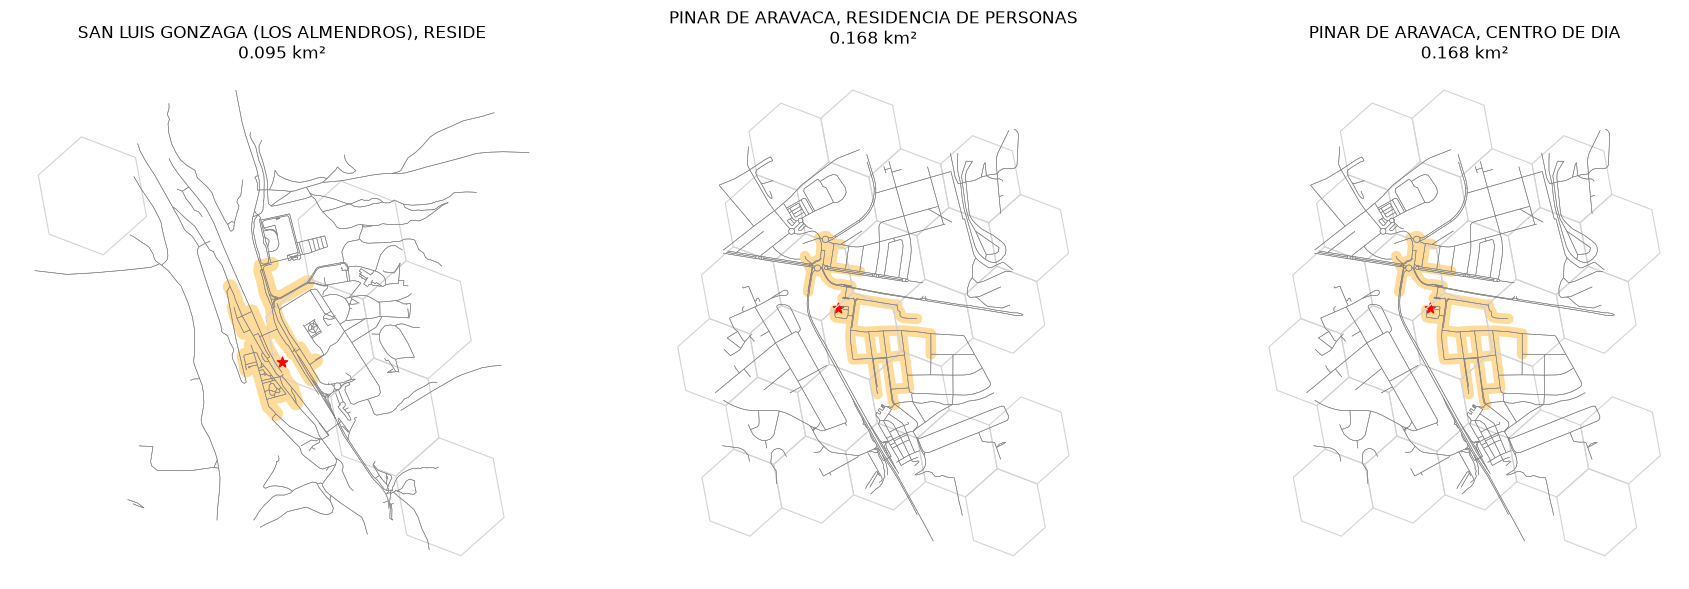

**Observacion:**El mapa resuelve la duda: son isócronas reales, no un error de la red.
**Primer centro (San Luis Gonzaga):** está encajado en un corredor de líneas paralelas, que por su forma parecen una autovía y una vía de tren. Solo puede moverse a lo largo del corredor, porque hay pocos cruces para pasar al otro lado.
**Segundo y tercer mapa:** son el mismo lugar (la residencia y el centro de día de Pinar de Aravaca comparten edificio). La isócrona llega a la línea que cruza en diagonal (probablemente la vía del tren) y al sur se extiende por las calles de una urbanización, pero no avanza hacia el oeste: ahí la red es muy escasa y con calles sin salida.

## 3. Hexágonos de cada isócrona y - asignamos a cada isócrona los hexágonos urbanos cuyo centro cae dentro

In [7]:
hexagonos_todos = gpd.read_file(RUTA_CLEAN + "hexagonos_h3.gpkg")
hexagonos = hexagonos_todos[hexagonos_todos["urbano"]].copy()
centroides = gpd.GeoDataFrame(hexagonos[["h3"]], geometry=hexagonos.centroid, crs=CRS_PROYECTO)

centros_hexagonos = gpd.sjoin(centroides, isocronas[["codigo", "geometry"]], how="inner", predicate="within")
centros_hexagonos = centros_hexagonos[["codigo", "h3"]].reset_index(drop=True)

hexagonos_por_centro = centros_hexagonos.groupby("codigo").size()
print("Pares centro-hexágono:", len(centros_hexagonos))
print("Hexágonos distintos en alguna isócrona:", centros_hexagonos["h3"].nunique())
hexagonos_por_centro.describe()

Pares centro-hexágono: 2749
Hexágonos distintos en alguna isócrona: 1024


count    436.000000
mean       6.305046
std        2.100043
min        1.000000
25%        5.000000
50%        7.000000
75%        8.000000
max       11.000000
dtype: float64

**Observación:** hay 2.749 pares centro-hexágono y 1.024 hexágonos distintos, que son los candidatos del optimizador. Cada isócrona tiene de media 6 hexágonos (entre 1 y 11), coherente con su área media.

- revisamos si algún centro se queda sin hexágonos

In [8]:
centros_sin_hexagono = set(isocronas["codigo"]) - set(centros_hexagonos["codigo"])
print("Centros sin ningún hexágono en su isócrona:", len(centros_sin_hexagono))

Centros sin ningún hexágono en su isócrona: 3


**Observación:** 3 centros se quedan sin hexágonos, porque sus isócronas son tan pequeñas que ningún centro de hexágono cae dentro.

**Decisión:** se añade siempre a cada isócrona el hexágono en el que está el propio centro. Así los 3 centros con isócronas muy pequeñas (sin ningún centro de hexágono dentro) tienen al menos un hexágono, y en el resto se garantiza que su hexágono cuenta. Es coherente con el simulador, que trabaja con el hexágono de cada centro.

- añadimos el hexágono de cada centro y quitamos los pares repetidos

In [9]:
hexagono_propio = gpd.sjoin(centros[["codigo", "geometry"]], hexagonos[["h3", "geometry"]], how="inner", predicate="within")
hexagono_propio = hexagono_propio[["codigo", "h3"]]

centros_hexagonos = pd.concat([centros_hexagonos, hexagono_propio], ignore_index=True)
centros_hexagonos = centros_hexagonos.drop_duplicates().reset_index(drop=True)

hexagonos_por_centro = centros_hexagonos.groupby("codigo").size()
print("Pares centro-hexágono:", len(centros_hexagonos))
print("Hexágonos distintos en alguna isócrona:", centros_hexagonos["h3"].nunique())
print("Centros sin hexágonos:", len(set(isocronas["codigo"]) - set(centros_hexagonos["codigo"])))
hexagonos_por_centro.describe()

Pares centro-hexágono: 2822
Hexágonos distintos en alguna isócrona: 1079
Centros sin hexágonos: 0


count    439.000000
mean       6.428246
std        2.045984
min        1.000000
25%        5.000000
50%        7.000000
75%        8.000000
max       11.000000
dtype: float64

**Observación:** tras añadir el hexágono de cada centro, los 439 centros tienen al menos un hexágono en su isócrona. Se suman 73 pares (de 2.749 a 2.822) y 55 hexágonos candidatos nuevos (de 1.024 a 1.079): en 73 centros, su propio hexágono no se contaba porque su centro geométrico quedaba fuera de la isócrona. Cada isócrona tiene ahora de media 6,4 hexágonos.

## 4. Comprobación visual y - dibujamos la isócrona de tres centros con la red y los hexágonos

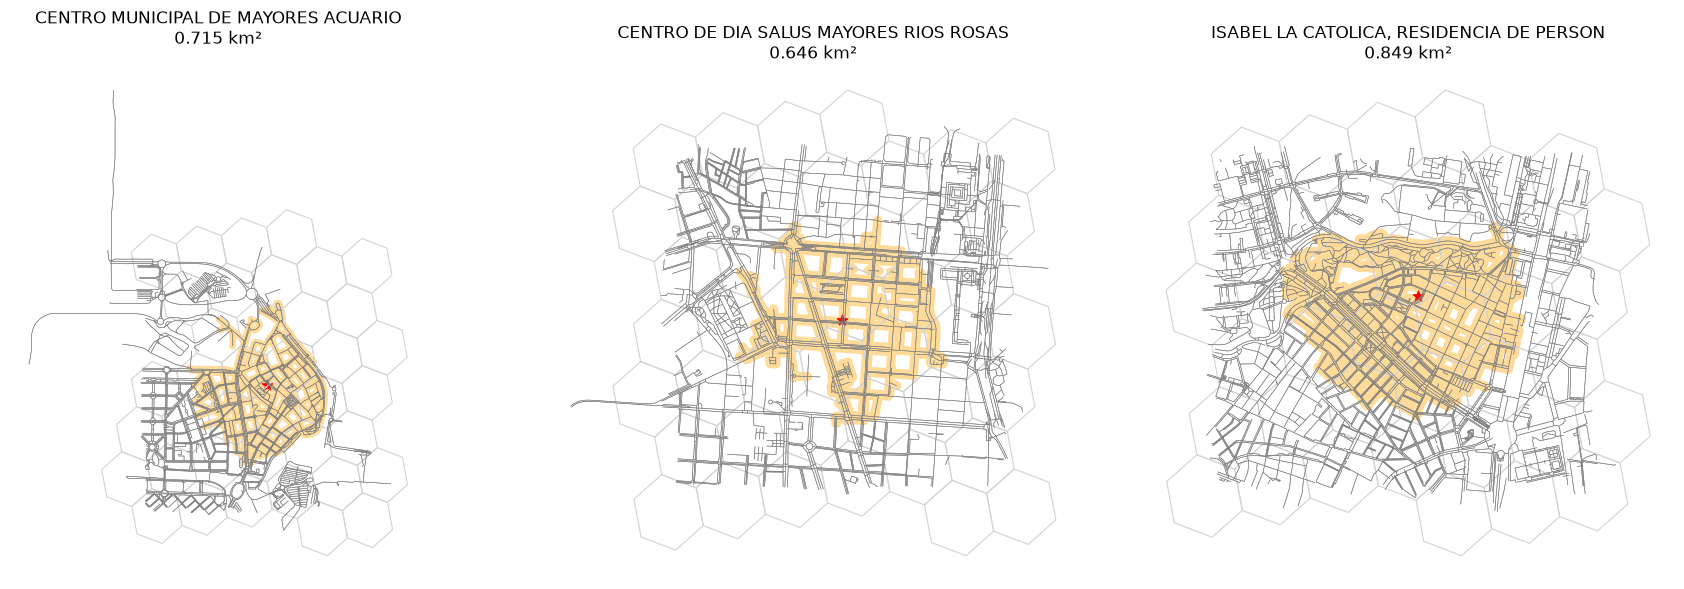

In [10]:
ejemplos = isocronas.sample(3, random_state=0)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for eje, (_, fila) in zip(axes, ejemplos.iterrows()):
    xmin, ymin, xmax, ymax = fila.geometry.buffer(300).bounds
    hexagonos.cx[xmin:xmax, ymin:ymax].boundary.plot(ax=eje, color="lightgrey", linewidth=0.8)
    tramos.cx[xmin:xmax, ymin:ymax].plot(ax=eje, color="grey", linewidth=0.4)
    gpd.GeoSeries([fila.geometry], crs=CRS_PROYECTO).plot(ax=eje, color="orange", alpha=0.4)
    centros[centros["codigo"] == fila["codigo"]].plot(ax=eje, color="red", markersize=60, marker="*")
    eje.set_title(f"{fila['nombre'][:40]}\n{fila['area_km2']} km²")
    eje.set_axis_off()
plt.tight_layout()
plt.show()

**Observación del mapa al azar:** en los tres centros elegidos al azar, la isócrona sigue la forma de las calles: es más compacta en las cuadrículas densas, como Ríos Rosas, y se estira a lo largo de las vías principales. Con áreas de 0,65 a 0,85 km², ocupan entre 6 y 8 hexágonos del entorno de cada centro

- guardamos las isócronas y la relación centro-hexágono

In [11]:
isocronas.to_file(RUTA_CLEAN + "isocronas_normales.gpkg", driver="GPKG")
centros_hexagonos.to_csv(RUTA_CLEAN + "centros_hexagonos.csv", index=False)

In [ ]:
## 5. Isócrona confortable

**Decisión:** cada tramo de calle tiene una "longitud vivida" que penaliza el calor, siguiendo la formulación de CoolWalks (Wolf y colaboradores, 2024): coste = longitud × (1 + (α − 1) × calor del tramo), donde α es la aversión al calor (un metro con el máximo calor se vive como α metros frescos). Es la idea del método isocalor (Huber y colaboradores, 2025): una isócrona que evita la exposición al calor. Se usa α = 1,5 como valor central (el límite de lo realista según CoolWalks, adecuado para personas mayores, más sensibles al calor) y se comprueba la sensibilidad con α = 1,25 y α = 2.

**Limitación:** CoolWalks usa la sombra de cada calle; aquí se usa la temperatura de superficie del hexágono por el que pasa el tramo como indicador del calor.

- asignamos a cada tramo la temperatura del hexágono en el que está su punto medio

In [12]:
puntos_medios = gpd.GeoDataFrame(geometry=tramos.geometry.interpolate(0.5, normalized=True), crs=CRS_PROYECTO)
puntos_medios = gpd.sjoin_nearest(puntos_medios, hexagonos_todos[["lst", "geometry"]], how="left")
puntos_medios = puntos_medios[~puntos_medios.index.duplicated()]
tramos["lst"] = puntos_medios["lst"]

print("Tramos sin temperatura:", tramos["lst"].isnull().sum())
tramos["lst"].describe()

Tramos sin temperatura: 0


count    668278.000000
mean         44.910246
std           2.529407
min          34.618230
25%          43.262755
50%          44.622232
75%          46.478672
max          55.738333
Name: lst, dtype: float64

**Observación:** todos los tramos tienen temperatura; la mediana es de 44,6 °C y el rango va de 34,6 a 55,7 °C.

**Decisión:** el calor del tramo se pasa a una escala de 0 a 1 entre los percentiles 5 y 95 de la temperatura de los hexágonos urbanos: 0 es una calle fresca y 1 una calle muy caliente. Usar percentiles en lugar del mínimo y el máximo evita que unos pocos valores extremos (agua, pistas del aeropuerto) compriman la escala.

- calculamos el calor de cada tramo entre 0 y 1

In [13]:
lst_p5 = hexagonos["lst"].quantile(0.05)
lst_p95 = hexagonos["lst"].quantile(0.95)
tramos["calor"] = ((tramos["lst"] - lst_p5) / (lst_p95 - lst_p5)).clip(0, 1)

print("Percentil 5:", round(lst_p5, 2), "°C - percentil 95:", round(lst_p95, 2), "°C")
tramos["calor"].describe()

Percentil 5: 41.09 °C - percentil 95: 50.46 °C


count    668278.000000
mean          0.413084
std           0.249242
min           0.000000
25%           0.232070
50%           0.377224
75%           0.575439
max           1.000000
Name: calor, dtype: float64

**Observación:** el calor de cada tramo se expresa en una escala sin unidades de 0 a 1, donde 0 corresponde a 41,1 °C o menos (percentil 5) y 1 a 50,5 °C o más (percentil 95). El tramo típico tiene un calor de 0,38, que equivale a unos 44,6 °C.

In [ ]:
- función que calcula el polígono de la isócrona de un centro con un peso dado (longitud o coste vivido)

In [14]:
def calcular_isocrona(nodo, peso):
    """Devuelve el polígono de las calles alcanzadas desde un nodo hasta la distancia máxima, y el nº de nodos alcanzados."""
    alcanzados = nx.single_source_dijkstra_path_length(red, nodo, cutoff=DISTANCIA_MAXIMA, weight=peso)
    tramos_alcanzados = tramos[
        tramos.index.get_level_values("u").isin(alcanzados) &
        tramos.index.get_level_values("v").isin(alcanzados)
    ]
    return tramos_alcanzados.buffer(MARGEN_CALLE).union_all(), len(alcanzados)

- calculamos la isócrona confortable de cada centro con los tres valores de α y su % de confort

In [15]:
valores_alfa = [1.25, 1.5, 2]
poligonos_central = []

for alfa in valores_alfa:
    nombre_peso = f"coste_{alfa}"
    tramos[nombre_peso] = tramos["length"] * (1 + (alfa - 1) * tramos["calor"])
    nx.set_edge_attributes(red, tramos[nombre_peso].to_dict(), nombre_peso)

    areas = []
    for nodo in centros["nodo"]:
        poligono, _ = calcular_isocrona(nodo, nombre_peso)
        areas.append(poligono.area / 1_000_000)
        if alfa == 1.5:
            poligonos_central.append(poligono)

    isocronas[f"area_conf_{alfa}"] = np.round(areas, 3)
    isocronas[f"pct_confort_{alfa}"] = (isocronas[f"area_conf_{alfa}"] / isocronas["area_km2"] * 100).round(1)
    print(f"α = {alfa}: terminado")

isocronas[["pct_confort_1.25", "pct_confort_1.5", "pct_confort_2"]].describe()

α = 1.25: terminado
α = 1.5: terminado
α = 2: terminado


,pct_confort_1.25,pct_confort_1.5,pct_confort_2
count,439.000000,439.000000,439.000000
mean,85.809795,74.721412,58.838497
std,6.148733,9.195080,12.929448
min,55.300000,39.500000,19.500000
25%,82.200000,68.650000,50.200000
50%,85.700000,73.900000,57.100000
75%,89.500000,80.500000,66.700000
max,100.000000,100.000000,100.000000


**Observación:** con el valor central (α = 1,5), un centro típico puede recorrer sin exceso de calor el 74 % del área de su isócrona normal; el peor, solo el 39,5 %. Con α = 1,25 la media sube al 86 % y con α = 2 baja al 59 %: el nivel depende del supuesto, pero, como se ve a continuación, el orden de los centros apenas cambia.

- comprobamos si el orden de los centros según su % de confort cambia con el valor de α (correlación de Spearman)

In [16]:
isocronas[["pct_confort_1.25", "pct_confort_1.5", "pct_confort_2"]].corr(method="spearman").round(3)

,pct_confort_1.25,pct_confort_1.5,pct_confort_2
pct_confort_1.25,1.000,0.923,0.890
pct_confort_1.5,0.923,1.000,0.961
pct_confort_2,0.890,0.961,1.000


Observación: el orden de los centros según su confort es casi el mismo con los tres valores de α (correlaciones de 0,89 a 0,96): α cambia el nivel de confort, pero no qué centros están peor. El supuesto no es determinante para las conclusiones.

- mapa de tres centros con la isócrona normal y la confortable (α = 1,5)

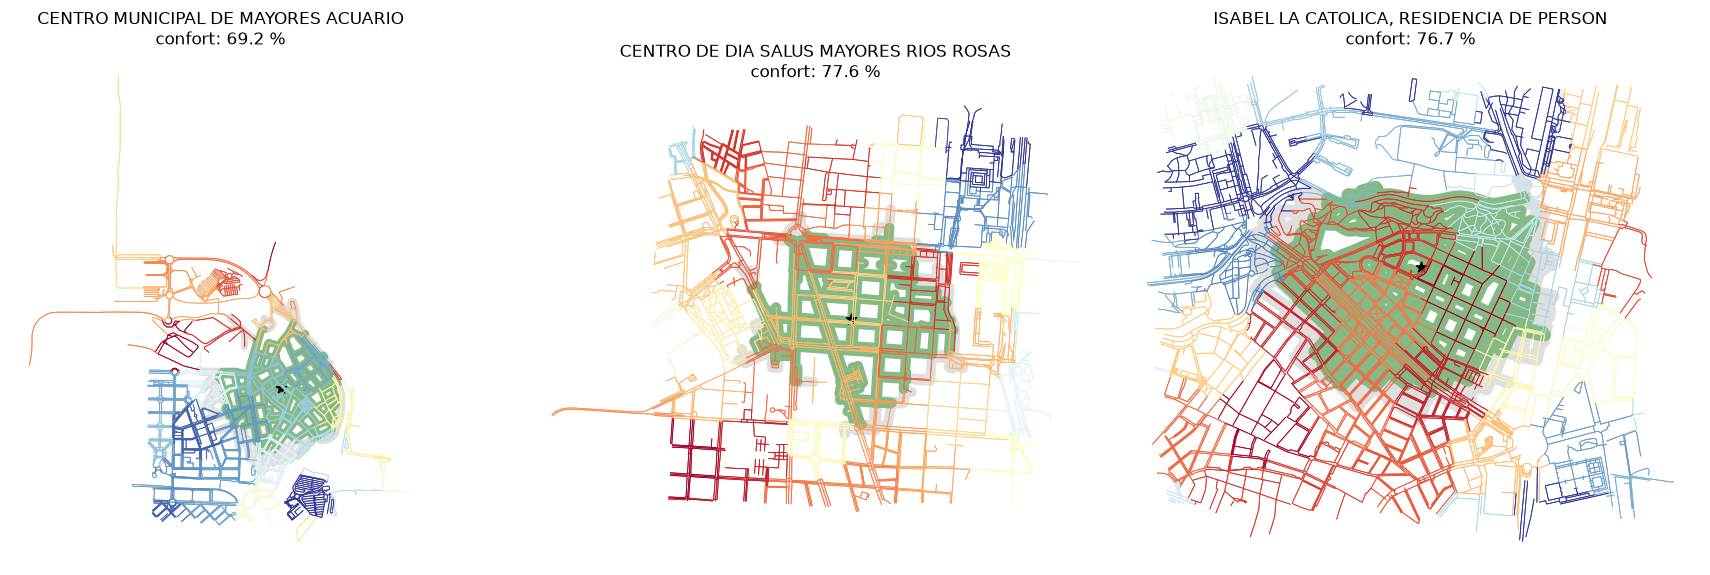

In [17]:
isocronas_confortables = gpd.GeoDataFrame(
    isocronas[["codigo", "nombre", "tipo_centro", "plazas", "area_km2", "area_conf_1.5", "pct_confort_1.5"]].copy(),
    geometry=poligonos_central,
    crs=CRS_PROYECTO
)

ejemplos = isocronas_confortables.sample(3, random_state=0)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for eje, (indice, fila) in zip(axes, ejemplos.iterrows()):
    xmin, ymin, xmax, ymax = isocronas.loc[indice, "geometry"].buffer(300).bounds
    tramos.cx[xmin:xmax, ymin:ymax].plot(ax=eje, column="calor", cmap="RdYlBu_r", linewidth=0.6)
    gpd.GeoSeries([isocronas.loc[indice, "geometry"]], crs=CRS_PROYECTO).plot(ax=eje, color="grey", alpha=0.25)
    gpd.GeoSeries([fila.geometry], crs=CRS_PROYECTO).plot(ax=eje, color="green", alpha=0.4)
    centros[centros["codigo"] == fila["codigo"]].plot(ax=eje, color="black", markersize=60, marker="*")
    eje.set_title(f"{fila['nombre'][:40]}\nconfort: {fila['pct_confort_1.5']} %")
    eje.set_axis_off()
plt.tight_layout()
plt.show()

Observación: la isócrona confortable (verde) es menor que la normal (gris) y se recorta sobre todo por las calles más calientes (rojas), mientras que mantiene las frescas (azules).

**Conclusión:** no existe un valor exacto de cuánto molesta el calor a una persona mayor al caminar (α), así que se probaron tres valores tomados del estudio CoolWalks (Wolf y colaboradores, 2024, arXiv:2405.01225), que considera realistas los valores de hasta 1,5. Cada uno da un porcentaje de confort distinto, pero los centros que salen peor son prácticamente los mismos con los tres valores de alfa (correlación de Spearman de 0,89 a 0,96). Por tanto, la elección de α no cambia qué centros necesitan actuar primero.

- guardamos las isócronas confortables y añadimos el % de confort a las normales

In [18]:
isocronas_confortables.to_file(RUTA_CLEAN + "isocronas_confortables.gpkg", driver="GPKG")
isocronas.to_file(RUTA_CLEAN + "isocronas_normales.gpkg", driver="GPKG")